# 05 · Multi-head attention – nhiều "góc nhìn" chạy song song

**Vị trí trong luồng dữ liệu:** văn bản → token → embedding (+ vị trí) → N khối Transformer (**multi-head attention** + feed-forward) → logits → token tiếp theo

Một head attention cho mỗi token **một** bộ trọng số, nên chỉ học được một kiểu quan hệ. Nhưng để đoán chữ tiếp theo
trong thơ lục bát, mô hình cần nhiều thông tin cùng lúc: chữ ngay trước là gì, câu đang ở chữ thứ mấy, chữ cuối câu
trên là gì để bắt vần... **Multi-head attention** chạy nhiều head song song, mỗi head trong một không gian nhỏ hơn
(`head_dim = d_model / n_head`), rồi ghép kết quả lại.

Trong notebook này bạn sẽ:

1. Cài multi-head "ngây thơ": một danh sách `SelfAttentionHead`, nối đầu ra lại.
2. Cài bản hiệu quả bằng `view`/`transpose` (đúng như `MultiHeadAttention` trong repo), theo dõi **shape** ở từng bước.
3. Chứng minh hai cách cho kết quả giống hệt nhau.
4. Vẽ attention của từng head trên một câu thơ.

⏱ Thời gian chạy: vài giây.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "vietformer").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import math

import matplotlib.pyplot as plt
import torch

from vietformer import viz
from vietformer.attention import MultiHeadAttention, SelfAttentionHead, causal_mask
from vietformer.data import get_tokenizer
from vietformer.embedding import TokenEmbedding
from vietformer.utils import set_seed

viz.set_style()
set_seed(0)

## 1. Cách ngây thơ: nhiều head riêng rẽ rồi nối lại

Quy ước ký hiệu dùng trong cả repo: `B` = số chuỗi trong batch, `T` = số token mỗi chuỗi, `C` = `d_model` = số chiều
mỗi vector. Ta dùng số nhỏ để dễ theo dõi: `B = 2`, `T = 5`, `C = 8`, `n_head = 2`, nên `head_dim = 4`.

In [2]:
B, T, d_model, n_head = 2, 5, 8, 2
head_dim = d_model // n_head
x = torch.randn(B, T, d_model)

heads = [SelfAttentionHead(d_model, head_dim, block_size=16) for _ in range(n_head)]
outputs = [head(x) for head in heads]
for i, o in enumerate(outputs):
    print(f"head {i}: {tuple(x.shape)} -> {tuple(o.shape)}")
concatenated = torch.cat(outputs, dim=-1)  # nối theo chiều cuối
print("nối lại:", tuple(concatenated.shape))

head 0: (2, 5, 8) -> (2, 5, 4)
head 1: (2, 5, 8) -> (2, 5, 4)
nối lại: (2, 5, 8)


Mỗi head có bộ `W_Q`, `W_K`, `W_V` riêng kích thước `C × head_dim`, tạo ra đầu ra `head_dim` chiều. Nối `n_head` đầu
ra lại ta được đúng `C` chiều. Cuối cùng một lớp `Linear` (`proj`) **trộn** thông tin từ các head với nhau.

Cách này dễ hiểu nhưng chậm: các head chạy lần lượt trong vòng lặp Python, mỗi head làm vài phép nhân ma trận nhỏ.

## 2. Cách hiệu quả: một phép nhân lớn + view/transpose

Ý tưởng: xếp `W_Q` của tất cả các head cạnh nhau thành **một** ma trận `C × C`. Một phép nhân cho ra query của mọi
head cùng lúc; head `h` chỉ việc lấy các chiều `[h·head_dim, (h+1)·head_dim)`. Sau đó ta "xếp lại" tensor để trục
head đứng riêng, và mọi head được tính song song bằng phép nhân ma trận theo lô (batched matmul).

Theo dõi shape từng bước, dùng chính các lớp của `MultiHeadAttention`:

In [3]:
mha = MultiHeadAttention(d_model, n_head, block_size=16).eval()

q = mha.query(x)
print(f"1. q = query(x)              {tuple(q.shape)}   # (B, T, C)")
q = q.view(B, T, n_head, head_dim)
print(f"2. view                      {tuple(q.shape)}   # (B, T, n_head, head_dim): tách C thành n_head × head_dim")
q = q.transpose(1, 2)
print(f"3. transpose(1, 2)           {tuple(q.shape)}   # (B, n_head, T, head_dim): đưa trục head lên trước T")
k = mha.split_heads(mha.key(x))      # cùng cách cho K và V
v = mha.split_heads(mha.value(x))
print(f"   k, v                      {tuple(k.shape)}")

scores = q @ k.transpose(-2, -1) / math.sqrt(head_dim)
print(f"4. q @ kᵀ / √head_dim        {tuple(scores.shape)}   # (B, n_head, T, T): mỗi head một ma trận T × T")
weights = torch.softmax(scores.masked_fill(~causal_mask(T), float("-inf")), dim=-1)
out = weights @ v
print(f"5. weights @ v               {tuple(out.shape)}   # (B, n_head, T, head_dim)")
out = out.transpose(1, 2)
print(f"6. transpose(1, 2)           {tuple(out.shape)}   # (B, T, n_head, head_dim)")
out = out.contiguous().view(B, T, d_model)
print(f"7. contiguous().view         {tuple(out.shape)}   # (B, T, C): nối các head")
out = mha.proj(out)
print(f"8. proj                      {tuple(out.shape)}   # (B, T, C): trộn thông tin giữa các head")

print("\nGiống hệt mha(x)?", torch.allclose(out, mha(x), atol=1e-6))

1. q = query(x)              (2, 5, 8)   # (B, T, C)
2. view                      (2, 5, 2, 4)   # (B, T, n_head, head_dim): tách C thành n_head × head_dim
3. transpose(1, 2)           (2, 2, 5, 4)   # (B, n_head, T, head_dim): đưa trục head lên trước T
   k, v                      (2, 2, 5, 4)
4. q @ kᵀ / √head_dim        (2, 2, 5, 5)   # (B, n_head, T, T): mỗi head một ma trận T × T
5. weights @ v               (2, 2, 5, 4)   # (B, n_head, T, head_dim)
6. transpose(1, 2)           (2, 5, 2, 4)   # (B, T, n_head, head_dim)
7. contiguous().view         (2, 5, 8)   # (B, T, C): nối các head
8. proj                      (2, 5, 8)   # (B, T, C): trộn thông tin giữa các head

Giống hệt mha(x)? True


`view` **không di chuyển dữ liệu**, nó chỉ đổi cách "nhìn" vào cùng một dãy số. Ví dụ, vector query 8 chiều của token
đầu tiên được cắt làm 2 nửa: nửa đầu cho head 0, nửa sau cho head 1:

In [4]:
q_full = mha.query(x)[0, 0]                      # query của token 0, chuỗi 0: (C,) = (8,)
q_split = mha.split_heads(mha.query(x))[0, :, 0]  # cùng token đó sau khi tách: (n_head, head_dim) = (2, 4)
print("trước khi tách:", q_full.detach())
print("sau khi tách  :\n", q_split.detach())

trước khi tách: tensor([ 0.3775,  0.2798,  0.6872, -0.1718,  0.4391, -0.3845,  0.2358,  0.4569])
sau khi tách  :
 tensor([[ 0.3775,  0.2798,  0.6872, -0.1718],
        [ 0.4391, -0.3845,  0.2358,  0.4569]])


> **Vì sao cần `.contiguous()`?** `transpose` cũng không chép dữ liệu, nó chỉ đổi thứ tự đọc. Sau `transpose`, các số
> của một token không còn nằm liền nhau trong bộ nhớ, trong khi `view` đòi hỏi điều đó. `.contiguous()` chép dữ liệu
> sang một vùng nhớ mới đúng thứ tự (thay vào đó có thể dùng `.reshape`, hàm này tự chép khi cần).

## 3. Hai cách cho kết quả giống hệt nhau

Chép trọng số: head `h` của cách ngây thơ dùng hàng `[h·head_dim, (h+1)·head_dim)` của ma trận lớn. (Nhớ là
`nn.Linear` lưu `weight` dạng `(out, in)`, nên "cột" của `W_Q` trong công thức là "hàng" của `weight`.)

In [5]:
with torch.no_grad():
    for h, head in enumerate(heads):
        rows = slice(h * head_dim, (h + 1) * head_dim)
        head.query.weight.copy_(mha.query.weight[rows])
        head.key.weight.copy_(mha.key.weight[rows])
        head.value.weight.copy_(mha.value.weight[rows])

naive = mha.proj(torch.cat([head(x) for head in heads], dim=-1))
print("Cách ngây thơ == cách reshape?", torch.allclose(naive, mha(x), atol=1e-6))

n_naive = sum(p.numel() for head in heads for p in head.parameters())
n_fused = sum(p.numel() for layer in (mha.query, mha.key, mha.value) for p in layer.parameters())
print(f"Tham số Q, K, V: ngây thơ {n_naive} = gộp {n_fused} = 3 × C × C = {3 * d_model * d_model}")

Cách ngây thơ == cách reshape? True
Tham số Q, K, V: ngây thơ 192 = gộp 192 = 3 × C × C = 192


Số tham số không đổi: `n_head` head nhỏ (mỗi head `3 × C × head_dim`) bằng đúng một head lớn `3 × C × C`. Chia thành
nhiều head **không tốn thêm tham số hay phép tính**; nó chỉ chia không gian `C` chiều thành nhiều không gian con độc lập.

## 4. Nhiều head trên một câu thơ thật

Cấu hình như MiniGPT: `d_model = 128`, `n_head = 4` (mỗi head 32 chiều). Trọng số vẫn ngẫu nhiên, nhưng ta đã thấy
mỗi head cho một ma trận attention **khác nhau** cho cùng một câu.

vào: (1, 17) → ra: (1, 17, 128) | trọng số attention: (1, 4, 17, 17)


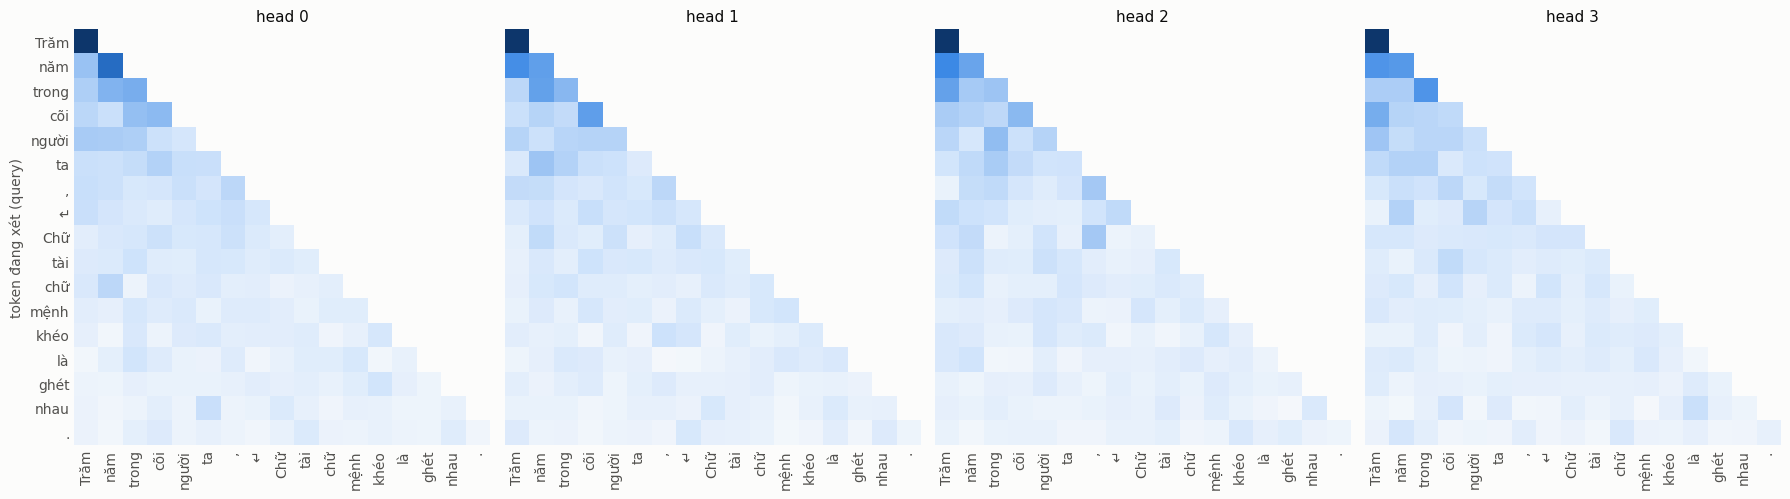

In [6]:
tokenizer = get_tokenizer()
text = "Trăm năm trong cõi người ta,\nChữ tài chữ mệnh khéo là ghét nhau."
idx = torch.tensor([tokenizer.encode(text)])
labels = tokenizer.display_tokens(idx[0])

embedding = TokenEmbedding(tokenizer.vocab_size, d_model=128)
mha_big = MultiHeadAttention(d_model=128, n_head=4, block_size=64).eval()
with torch.no_grad():
    y = mha_big(embedding(idx))
print("vào:", tuple(idx.shape), "→ ra:", tuple(y.shape), "| trọng số attention:", tuple(mha_big.last_attn.shape))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for h, ax in enumerate(axes):
    viz.plot_attention(mha_big.last_attn[0, h], labels, ax=ax, colorbar=False, title=f"head {h}")
    ax.set_xlabel("")
    if h > 0:
        ax.set_ylabel("")
        ax.set_yticklabels([])
plt.tight_layout()
plt.show()

Sau khi huấn luyện, các head có thể chuyên môn hóa, mỗi head theo dõi một kiểu quan hệ riêng. Notebook 08 sẽ đo điều
đó trên MiniGPT đã học (ví dụ: có những head ưu tiên nhìn về các dấu xuống dòng để biết câu thơ hiện tại bắt đầu từ
đâu). Đó là lý do ta muốn nhiều head thay vì một.

## Tóm tắt

* Multi-head = nhiều head attention song song, mỗi head làm việc trong `head_dim = d_model / n_head` chiều.
* Cài đặt hiệu quả: một phép nhân `C × C` cho Q (và K, V) của mọi head, rồi
  `(B, T, C) → view → (B, T, n_head, head_dim) → transpose → (B, n_head, T, head_dim)`.
* Sau attention làm ngược lại để nối các head, rồi `proj` trộn thông tin giữa các head.
* Số tham số không đổi so với một head lớn.

**Tiếp theo:** notebook 06 ghép attention với LayerNorm, residual và feed-forward thành một khối Transformer.

---

## Bài tập

Đáp án: `solutions/05_multi_head_attention.md`

**Bài 1.** Với `B = 3`, `T = 10`, `d_model = 64`, `n_head = 8`: hãy điền shape của tensor sau mỗi bước rồi kiểm
tra bằng code.

In [7]:
# TODO: điền shape bạn dự đoán (dạng tuple), rồi chạy ô này để kiểm tra
predicted = {
    "q sau query(x)": None,
    "q sau split_heads": None,
    "scores = q @ kᵀ": None,
    "out sau khi nối head": None,
}

x3 = torch.randn(3, 10, 64)
mha3 = MultiHeadAttention(64, 8, block_size=16)
q3 = mha3.split_heads(mha3.query(x3))
actual = {
    "q sau query(x)": tuple(mha3.query(x3).shape),
    "q sau split_heads": tuple(q3.shape),
    "scores = q @ kᵀ": tuple((q3 @ q3.transpose(-2, -1)).shape),
    "out sau khi nối head": tuple(mha3(x3).shape),
}
for name in actual:
    print(f"{name:22} dự đoán {predicted[name]}  thực tế {actual[name]}")

q sau query(x)         dự đoán None  thực tế (3, 10, 64)
q sau split_heads      dự đoán None  thực tế (3, 8, 10, 8)
scores = q @ kᵀ        dự đoán None  thực tế (3, 8, 10, 10)
out sau khi nối head   dự đoán None  thực tế (3, 10, 64)


**Bài 2.** Thử `MultiHeadAttention(d_model=30, n_head=4, block_size=16)`. Lỗi gì xảy ra và vì sao? Hãy chọn một
`n_head` hợp lệ cho `d_model = 30`.

In [8]:
# TODO: bọc trong try/except để xem thông báo lỗi

**Bài 3.** Lớp `proj` ở cuối có thật sự cần thiết không? Điều gì sẽ mất đi nếu bỏ nó (gợi ý: khi không có `proj`,
chiều thứ 0 của đầu ra phụ thuộc vào những head nào)?